In [1]:
import sys
from pathlib import Path


PROJECT_ROOT = Path.cwd().resolve().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_fashion_mnist
from src.preprocessing import (
    flatten_images,
    scale_pixels,
    create_validation_split
)

In [2]:
X_train, y_train, X_test, y_test = load_fashion_mnist()

In [3]:
X_train_flat = flatten_images(X_train)
X_test_flat = flatten_images(X_test)

print(X_train_flat.shape)
print(X_test_flat.shape)

(60000, 784)
(10000, 784)


In [4]:
X_train_scaled = scale_pixels(X_train_flat)
X_test_scaled = scale_pixels(X_test_flat)

In [5]:
print("Training range:",
      X_train_scaled.min(),
      X_train_scaled.max())

print("Testing range:",
      X_test_scaled.min(),
      X_test_scaled.max())

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training range: 0.0 1.0
Testing range: 0.0 1.0
Training shape: (60000, 784)
Testing shape: (10000, 784)


In [6]:
assert X_train_scaled.min() >= 0
assert X_train_scaled.max() <= 1

assert X_test_scaled.min() >= 0
assert X_test_scaled.max() <= 1

In [7]:
X_fit, X_val, y_fit, y_val = create_validation_split(
    X_train_scaled,
    y_train
)

In [8]:
print("Training subset:")
print("X_fit:", X_fit.shape)
print("y_fit:", y_fit.shape)

print("\nValidation subset:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nOfficial test set:")
print("X_test:", X_test_scaled.shape)
print("y_test:", y_test.shape)

Training subset:
X_fit: (48000, 784)
y_fit: (48000,)

Validation subset:
X_val: (12000, 784)
y_val: (12000,)

Official test set:
X_test: (10000, 784)
y_test: (10000,)


In [9]:
import numpy as np

print("Training class counts:")
print(np.bincount(y_fit))

print("\nValidation class counts:")
print(np.bincount(y_val))

Training class counts:
[4800 4800 4800 4800 4800 4800 4800 4800 4800 4800]

Validation class counts:
[1200 1200 1200 1200 1200 1200 1200 1200 1200 1200]


### Training and Validation Split

The official Fashion-MNIST test set is preserved unchanged for final
evaluation. A stratified 80/20 split of the official 60,000-image
training set is used to create model-fitting and validation subsets.

This produces 48,000 training images and 12,000 validation images.
Stratification preserves the class distribution across both subsets.

A random seed of 42 is used to make the split reproducible.

In [10]:
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

In [11]:
pca_analysis = PCA(
    n_components=None,
    svd_solver="full"
)

pca_analysis.fit(X_fit)

,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'full'
,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [12]:
print("Original number of features:", X_fit.shape[1])
print("Number of PCA components:", len(pca_analysis.explained_variance_ratio_))

print(
    "Total explained variance:",
    pca_analysis.explained_variance_ratio_.sum()
)

Original number of features: 784
Number of PCA components: 784
Total explained variance: 1.0


In [13]:
cumulative_variance = np.cumsum(
    pca_analysis.explained_variance_ratio_
)

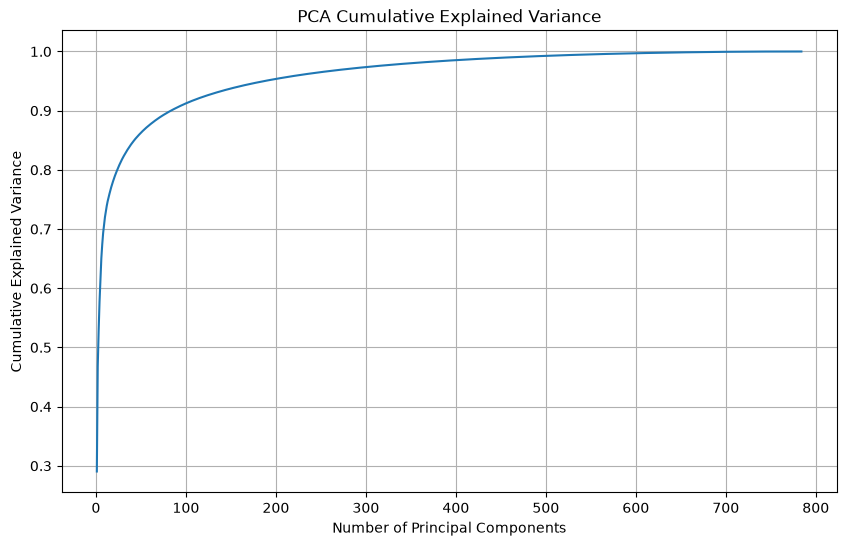

In [14]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")

plt.grid(True)
plt.show()

In [15]:
thresholds = [0.90, 0.95, 0.99]

for threshold in thresholds:
    n_components = np.searchsorted(
        cumulative_variance,
        threshold
    ) + 1

    print(
        f"{threshold:.0%} variance -> "
        f"{n_components} components"
    )

90% variance -> 84 components
95% variance -> 187 components
99% variance -> 459 components


## PCA Explained-Variance Analysis

PCA was fitted exclusively on the model-fitting subset of the
official Fashion-MNIST training data. Neither the validation subset
nor the official test set was used to fit PCA.

The cumulative explained-variance curve shows how much of the
variance in the original 784-dimensional pixel representation is
retained as additional principal components are included.

The final number of PCA components will be selected using a stated
criterion before model comparison.